## Data Analysis from Nature Paper

Paper and original data source can be found [here](https://www.nature.com/articles/s41684-023-01213-1)

## Nature breeding-planning dataset integration

This notebook merges the breeding-planning tables from the Nature paper into a single analysis-friendly dataset.

The key files are loaded from `data/nature/` and joined on the target number of pups.


In [7]:
# Installation of models if needed
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data' / 'nature'

plt.style.use('seaborn-v0_8')
sns.set_theme(style='whitegrid')
print(f'Working directory: {ROOT}')


Working directory: /home/user1/unsw/scif3000-analysis


In [9]:
# Load the base probability distribution and planning tables
dist = pd.read_csv(DATA_DIR / 'nature_1_processed.csv')
targets = pd.read_csv(DATA_DIR / 'nature_merged_targets.csv')
two_group = pd.read_csv(DATA_DIR / 'nature_2c_processed.csv')

print('Distribution rows:', len(dist))
print('Target planning rows:', len(targets))
print('Two-group rows:', len(two_group))
dist.head()


Distribution rows: 202
Target planning rows: 2178
Two-group rows: 2500


,animals_born,variable,value
0,0,b3,0.0270
1,1,b3,0.0012
2,2,b3,0.0042
3,3,b3,0.0100
4,4,b3,0.0178


In [10]:
# Display the merged planning table
targets.head(12)


,target_pups,req_poisson,req_festing,req_mendel,animals_saved_fp_percent,animals_saved_pf_percent,confidence,breedings_at_50pct_confidence,breedings_balanced_sex,breedings_any_sex,breedings_one_sex_only
0,2,2,3,1,33,50,0.50,2,3,3,4
1,2,2,3,1,33,50,0.60,2,3,3,4
2,2,2,3,1,33,50,0.70,3,3,3,4
3,2,2,3,1,33,50,0.80,3,3,3,4
4,2,2,3,1,33,50,0.85,4,3,3,4
5,2,2,3,1,33,50,0.90,4,3,3,4
6,2,2,3,1,33,50,0.91,5,3,3,4
7,2,2,3,1,33,50,0.92,5,3,3,4
8,2,2,3,1,33,50,0.93,5,3,3,4
9,2,2,3,1,33,50,0.94,5,3,3,4


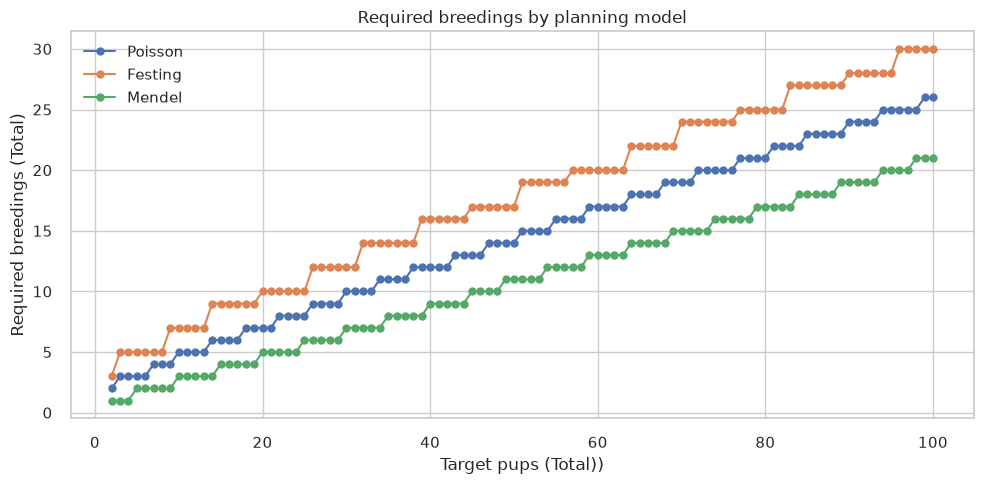

In [11]:
# Plot required breedings from the different model assumptions
targets.columns = [str(col).strip() for col in targets.columns]
required_cols = ['target_pups', 'req_poisson', 'req_festing', 'req_mendel']
missing = [col for col in required_cols if col not in targets.columns]
if missing:
    raise ValueError(f'Missing required columns in targets: {missing}')

plot_df = targets[required_cols].drop_duplicates().sort_values('target_pups')

plt.figure(figsize=(10, 5))
for col in ['req_poisson', 'req_festing', 'req_mendel']:
    plt.plot(plot_df['target_pups'], plot_df[col], marker='o', label=col.replace('req_', '').title())

plt.xlabel('Target pups (Total))')
plt.ylabel('Required breedings (Total)')
plt.title('Required breedings by planning model')
plt.legend()
plt.tight_layout()
plt.show()


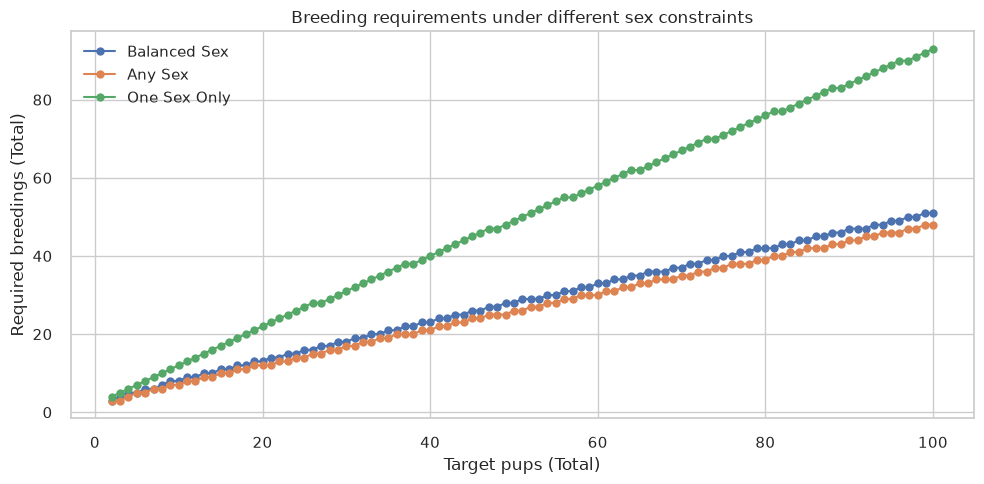

In [12]:
# Compare sex-specific breeding requirements
sex_df = targets[['target_pups', 'breedings_balanced_sex', 'breedings_any_sex', 'breedings_one_sex_only']].drop_duplicates().sort_values('target_pups')

plt.figure(figsize=(10, 5))
for col in ['breedings_balanced_sex', 'breedings_any_sex', 'breedings_one_sex_only']:
    plt.plot(sex_df['target_pups'], sex_df[col], marker='o', label=col.replace('breedings_', '').replace('_', ' ').title())

plt.xlabel('Target pups (Total)')
plt.ylabel('Required breedings (Total)')
plt.title('Breeding requirements under different sex constraints')
plt.legend()
plt.tight_layout()
plt.show()
